In [28]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from lightgbm import LGBMRanker
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import ndcg_score, average_precision_score
from typing import Dict, List, Optional, Union
import logging
import matplotlib.pyplot as plt
import seaborn as sns
import skfuzzy as fuzz
from skfuzzy import control as ctrl

In [29]:
label_encoders: Dict[str, LabelEncoder] = {}
scaler = MinMaxScaler()
feature_columns: List[str] = []
categorical_cols = ['brand', 'car_model', 'transmission', 'body_type', 'fuel_type', 'registration', 'accident']
numerical_cols = ['car_age', 'engine_capacity', 'travels', 'price']
metrics_history = []

# model = LGBMRanker(
#             objective="lambdarank",
#             metric="ndcg",
#             boosting_type="gbdt",
#             n_estimators=100,
#             importance_type="gain",
#             random_state=42
#         )
model = None
recommended_indices = None

## Load Dataset

In [30]:
# df = pd.read_csv('datasets/Bikroy1.csv', encoding='latin1')
df = pd.read_csv('datasets/Bikroy2.csv', encoding='latin1')
df.head(3)

,ï»¿id,car_name,brand,car_model,model_year,transmission,body_type,fuel_type,engine_capacity,travels,price,accident,registration
0,1,MarutiSuzukiWagonRUttara2012,MarutiSuzuki,WagonR,2012,Automatic,Hatchback,Octane,1500,60000.0,2550000.0,N,2025
1,2,ToyotaHiace2005,Toyota,Hiace,2005,Automatic,MPV,CNG,2000,32000.0,2000200.0,Y,2024
2,3,ToyotaAxio2009,Toyota,Axio,2009,Automatic,Hatchback,CNG,1500,25500.0,2245550.0,N,2023


In [31]:
df['car_age'] = 2024 - df['model_year']
df.head(3)

,ï»¿id,car_name,brand,car_model,model_year,transmission,body_type,fuel_type,engine_capacity,travels,price,accident,registration,car_age
0,1,MarutiSuzukiWagonRUttara2012,MarutiSuzuki,WagonR,2012,Automatic,Hatchback,Octane,1500,60000.0,2550000.0,N,2025,12
1,2,ToyotaHiace2005,Toyota,Hiace,2005,Automatic,MPV,CNG,2000,32000.0,2000200.0,Y,2024,19
2,3,ToyotaAxio2009,Toyota,Axio,2009,Automatic,Hatchback,CNG,1500,25500.0,2245550.0,N,2023,15


## Handle Missing Values

In [32]:
def _handle_missing_values(df: pd.DataFrame) -> pd.DataFrame :
    df_processed = df.copy()

    # Fill numerical missing values with median
    for col in numerical_cols:
        df_processed[col] = df_processed[col].fillna(df_processed[col].median())
    
    return df_processed

## Preprocessing

In [33]:
def preprocess_data(df: pd.DataFrame) -> pd.DataFrame :
    # handle missing value
    df_processed = _handle_missing_values(df)

    # Encode categorical variables
    for col in categorical_cols:
        if col not in label_encoders:
            label_encoders[col] = LabelEncoder()
            df_processed[col] = label_encoders[col].fit_transform(df_processed[col])
        else:
            # handle new categories in test data
            unique_values = df_processed[col].unique()
            if not set(unique_values).issubset(set(label_encoders[col].classes_)):
                # Create a mask for rows with unknown categories
                unknown_mask = ~df_processed[col].isin(label_encoders[col].classes_)
                # Replace unknown categories with the first category from training
                df_processed.loc[unknown_mask, col] = label_encoders[col].classes_[0]
            df_processed[col] = label_encoders[col].transform(df_processed[col])

    # Scale numerical features
    numerical_features = df_processed[numerical_cols]
    df_processed[numerical_cols] = scaler.fit_transform(numerical_features)

    
    global feature_columns
    feature_columns = categorical_cols + numerical_cols

    return df_processed

In [34]:
preprocess_data(df).head()

,ï»¿id,car_name,brand,car_model,model_year,transmission,body_type,fuel_type,engine_capacity,travels,price,accident,registration,car_age
0,1,MarutiSuzukiWagonRUttara2012,4,57,2012,0,4,3,0.090909,0.120134,0.001225,0,3,0.428571
1,2,ToyotaHiace2005,8,32,2005,0,5,0,0.318182,0.063987,0.000953,1,2,0.678571
2,3,ToyotaAxio2009,8,10,2009,0,4,0,0.090909,0.050953,0.001074,0,1,0.535714
3,4,ToyotaCorsa1999,8,19,1999,0,4,0,0.090909,0.180291,0.000516,0,1,0.892857
4,5,ToyotaCorolla2002,8,17,2002,0,8,0,0.090909,0.406041,0.001111,0,1,0.785714


In [35]:
def visualize_metrics(metrics_history: List[Dict[str, float]], 
                     figsize: tuple = (15, 8)) -> None:
    """
    Visualize training metrics history with multiple plots.
    
    Parameters:
    -----------
    metrics_history : List[Dict[str, float]]
        List of dictionaries containing metrics from each evaluation
    figsize : tuple, optional
        Figure size for the plots, by default (15, 8)
    """
    # Convert metrics history to DataFrame for easier plotting
    df_metrics = pd.DataFrame(metrics_history)
    
    # Create subplots
    fig, axes = plt.subplots(2, 1, figsize=figsize)
    fig.suptitle('Ranking Model Evaluation Metrics', fontsize=16, y=1.02)
    
    # Plot 1: NDCG metrics over time
    ndcg_cols = [col for col in df_metrics.columns if 'ndcg' in col]
    for col in ndcg_cols:
        axes[0].plot(df_metrics.index, df_metrics[col], marker='o', label=col)
    
    axes[0].set_title('NDCG Scores Over Time')
    axes[0].set_xlabel('Evaluation Step')
    axes[0].set_ylabel('NDCG Score')
    axes[0].grid(True, linestyle='--', alpha=0.7)
    axes[0].legend()
    
    # Plot 2: Accuracy over time
    axes[1].plot(df_metrics.index, df_metrics['accuracy'], 
                marker='o', color='green', label='Accuracy')
    axes[1].set_title('Accuracy Over Time')
    axes[1].set_xlabel('Evaluation Step')
    axes[1].set_ylabel('Accuracy Score')
    axes[1].grid(True, linestyle='--', alpha=0.7)
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

In [36]:
def visualize_group_metrics(group_metrics: List[Dict[str, float]], 
                          group_names: List[str] = None,
                          figsize: tuple = (12, 6)) -> None:
    """
    Visualize metrics across different groups with a heatmap.
    
    Parameters:
    -----------
    group_metrics : List[Dict[str, float]]
        List of dictionaries containing metrics for each group
    group_names : List[str], optional
        Names of the groups for labeling
    figsize : tuple, optional
        Figure size for the plot, by default (12, 6)
    """
    # Convert to DataFrame
    df_metrics = pd.DataFrame(group_metrics)
    
    if group_names is not None:
        df_metrics.index = group_names
    
    # Create heatmap
    plt.figure(figsize=figsize)
    sns.heatmap(df_metrics, 
                annot=True, 
                cmap='YlOrRd', 
                fmt='.3f',
                cbar_kws={'label': 'Score'})
    
    plt.title('Metrics Heatmap Across Groups', pad=20)
    plt.ylabel('Groups')
    plt.xlabel('Metrics')
    plt.tight_layout()
    plt.show()

In [37]:
def plot_metric_distribution(metrics_list: List[Dict[str, float]], 
                           metric_name: str,
                           figsize: tuple = (10, 6)) -> None:
    """
    Plot distribution of a specific metric across evaluations.
    
    Parameters:
    -----------
    metrics_list : List[Dict[str, float]]
        List of dictionaries containing metrics
    metric_name : str
        Name of the metric to plot
    figsize : tuple, optional
        Figure size for the plot, by default (10, 6)
    """
    values = [m[metric_name] for m in metrics_list if metric_name in m]
    
    plt.figure(figsize=figsize)
    
    # Create violin plot
    sns.violinplot(y=values)
    sns.swarmplot(y=values, color="white", alpha=0.5)
    
    plt.title(f'Distribution of {metric_name}')
    plt.ylabel('Score')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [38]:
def plot_all_metrics(metrics_history: List[Dict[str, float]], 
                    group_metrics: List[Dict[str, float]] = None,
                    group_names: List[str] = None) -> None:
    """
    Create all visualizations for metrics analysis.
    
    Parameters:
    -----------
    metrics_history : List[Dict[str, float]]
        List of dictionaries containing metrics from each evaluation
    group_metrics : List[Dict[str, float]], optional
        List of dictionaries containing metrics for each group
    group_names : List[str], optional
        Names of the groups for labeling
    """
    # Plot metrics over time
    visualize_metrics(metrics_history)
    
    # If group metrics are provided, plot group comparison
    if group_metrics is not None:
        visualize_group_metrics(group_metrics, group_names)
    
    # Plot distribution for each metric
    metric_names = metrics_history[0].keys()
    for metric in metric_names:
        plot_metric_distribution(metrics_history, metric)

In [39]:
def _validate_preferences(preferences: Dict) -> None:
        print('preferences = ', preferences.keys())
        """Validate user preferences."""
        required_prefs = {'brand', 'price', 'travels'}
        missing_prefs = required_prefs - set(preferences.keys())
        if missing_prefs:
            raise ValueError(f"Missing required preferences: {missing_prefs}")

In [40]:
def calculate_relevance_scores(df: pd.DataFrame, user_preferences: Dict) -> np.ndarray :
    _validate_preferences(user_preferences)
    scores = np.zeros(len(df))
    weights = {
                'price': 0.3,
                'travels': 0.2,
                'car_age': 0.15,
                'fuel_type': 0.15,
                'brand': 0.15,
                'engine_capacity': 0.15,
                'accident': 0.1
            }
    for feature, weight in weights.items():
        if feature in user_preferences:
            if feature in categorical_cols:
                try:
                    encoded_val = label_encoders[feature].transform([user_preferences[feature]])[0]
                    scores += weight * (df[feature] == encoded_val)
                except ValueError:
                            print(
                                f"Unknown category {user_preferences[feature]} for {feature}. Skipping."
                            )
            elif feature in numerical_cols:
                # Create a dummy array with all numerical features
                dummy_array = np.zeros((1, len(numerical_cols)))
                feature_idx = numerical_cols.index(feature)
                dummy_array[0, feature_idx] = user_preferences[feature]

                # Scale the dummy array
                scaled_array = scaler.transform(dummy_array)
                scaled_value = scaled_array[0, feature_idx]

                # Calculate similarity score
                diff = abs(df[feature] - scaled_value)
                max_diff = max(diff.max(), 1e-8)  # Avoid division by zero
                scores += weight * (1 - diff/max_diff)
                '''value = user_preferences[feature]
                print('value = ', value)
                print('feature = ', feature)
                scaled_value = scaler.transform([[value]])[0][0]
                diff = abs(df[feature] - scaled_value)
                scores += weight * (1 - diff)'''
                
        return scores

In [41]:
def _convert_to_ranking_labels(scores: np.ndarray, num_grades: int = 5) -> np.ndarray:
    """
    Convert continuous scores to discrete ranking labels.
    
    Args:
        scores (np.ndarray): Continuous relevance scores
        num_grades (int): Number of discrete grades (default: 5)
        
    Returns:
        np.ndarray: Discrete integer labels for ranking
    """
    # Use percentile-based binning to create discrete grades
    percentiles = np.linspace(0, 100, num_grades)
    thresholds = np.percentile(scores, percentiles)

    # Convert scores to discrete labels (0 to num_grades-1)
    discrete_labels = np.zeros_like(scores, dtype=int)
    for i in range(1, len(thresholds)):
        discrete_labels += (scores >= thresholds[i]).astype(int)
    
    return discrete_labels

## model Evaluation

In [42]:
def _evaluate_split(X: pd.DataFrame, y: np.ndarray, 
                       group_sizes: List[int], k_values: List[int]) -> Dict[str, float]:
        """
        Evaluate model performance on a data split using sklearn metrics.
        """
        predictions = model.predict(X)
        metrics = {}
        
        start_idx = 0
        ndcg_scores = {k: [] for k in k_values}
        ap_scores = []
        
        for group_size in group_sizes:
            end_idx = start_idx + group_size
            group_true = y[start_idx:end_idx]
            group_pred = predictions[start_idx:end_idx]
            
            # Calculate NDCG@k for each k
            for k in k_values:
                ndcg = ndcg_score(
                    np.array([group_true]), 
                    np.array([group_pred]), 
                    k=k
                )
                ndcg_scores[k].append(ndcg)
            
            # Calculate Average Precision
            # For average precision, ensure binary labels
            # Convert to binary relevance scores (1 for highest value, 0 for others)
            binary_true = np.zeros_like(group_true)
            binary_true[np.argmax(group_true)] = 1
        
            # Convert predictions to proper format
            binary_pred = np.zeros_like(group_pred)
            binary_pred[np.argmax(group_pred)] = 1
        
            # Calculate Average Precision on binary labels
            ap = np.mean(binary_true == binary_pred)  # Using accuracy instead of AP for ranking
            ap_scores.append(ap)
        
            start_idx = end_idx
        
        # Average metrics across groups
        metrics = {
            f'ndcg@{k}': np.mean(scores) 
            for k, scores in ndcg_scores.items()
        }
        metrics['map'] = np.mean(ap_scores)

        metrics_history.append(metrics)
        
        return metrics

In [43]:
def fit(df: pd.DataFrame, user_preferences_list: List[Dict]) -> None:
    try:
        df_processed = preprocess_data(df)
    
        # X = df_processed[feature_columns]

        all_features = []
        all_scores = []
        group_sizes = []

        for preferences in user_preferences_list:
                # Get features for current group
                X_group = df_processed[feature_columns].copy()

                # Calculate relevance scores for current preferences
                scores = calculate_relevance_scores(df_processed, preferences)

                # Convert continuous scores to discrete labels
                discrete_scores = _convert_to_ranking_labels(scores)
                print('discrete_scores = ', discrete_scores)

                # Append data
                all_features.append(X_group)
                all_scores.append(discrete_scores)
                group_sizes.append(len(X_group))
                '''scores = calculate_relevance_scores(df_processed, preferences)
                all_scores.extend(scores)
                group_sizes.append(len(df))'''
        
        # Concatenate all features and scores
        X = pd.concat(all_features, axis=0)
        y = np.concatenate(all_scores)

        # start new 
        # Create group indices
        group_ids = np.repeat(np.arange(len(group_sizes)), group_sizes)
        
        # Determine number of groups for validation
        validation_split = 0.2
        random_state = 42
        n_groups = len(group_sizes)
        n_val_groups = max(1, int(n_groups * validation_split))
        
        # Create a random split of groups
        np.random.seed(random_state)
        all_group_indices = np.arange(n_groups)
        val_group_indices = np.random.choice(
            all_group_indices, 
            size=n_val_groups, 
            replace=False
        )
        train_group_indices = np.array([
            idx for idx in all_group_indices 
            if idx not in val_group_indices
        ])
        
        # Create train/val masks
        train_mask = np.isin(group_ids, train_group_indices)
        val_mask = np.isin(group_ids, val_group_indices)
        
        # Split the data
        X_train, X_val = X[train_mask], X[val_mask]
        y_train, y_val = y[train_mask], y[val_mask]
        
        # Calculate group sizes for train and validation sets
        train_groups = [
            sum(group_ids[train_mask] == i) 
            for i in train_group_indices
            if sum(group_ids[train_mask] == i) > 0
        ]
        val_groups = [
            sum(group_ids[val_mask] == i) 
            for i in val_group_indices
            if sum(group_ids[val_mask] == i) > 0
        ]
        # end new

        # Configure label gains for ranking
        label_gains = [2 ** i - 1 for i in range(5)]  # NDCG-like gains
        print('label gains = ', label_gains)

        # y = np.array(all_scores)
        
        global model
        model = LGBMRanker(
            objective="lambdarank",
            metric="ndcg",
            label_gain=label_gains,
            n_estimators=100,
            learning_rate=0.1,
            max_depth=6,
            num_leaves=31,
            min_data_in_leaf=20,
            random_state=42
        )
        model.fit(
                # X, y,
                # group=group_sizes,
                X_train, y_train,
                group=train_groups,
                eval_set=[(X_val, y_val)],
                eval_group=[val_groups],
                eval_metric='ndcg',
            )
    
        # Evaluate on validation set
        val_metrics = _evaluate_split(
                X_val, y_val, 
                val_groups,
                k_values=[5, 10]
            )
            
        return val_metrics
    except Exception as e:
        print(f"Error in model training: {str(e)}")
        raise

In [44]:
# Sample preferences for training
sample_preferences = [
            {
                'brand': 'Toyota',
                'price': 25000,
                'travels': 50000,
                'car_age': 2019,
                'engine_capacity': 1500,
                'accident': False
            },
            {
                'brand': 'Honda',
                'price': 20000,
                'travels': 30000,
                'car_age': 2020,
                'engine_capacity': 1600,
                'accident': False
            }
        ]

fit(df, sample_preferences)

preferences =  dict_keys(['brand', 'price', 'travels', 'car_age', 'engine_capacity', 'accident'])
discrete_scores =  0       2
1       3
2       3
3       3
4       2
       ..
1138    2
1139    1
1140    2
1141    2
1142    2
Name: price, Length: 1143, dtype: int64
preferences =  dict_keys(['brand', 'price', 'travels', 'car_age', 'engine_capacity', 'accident'])
discrete_scores =  0       2
1       3
2       3
3       3
4       2
       ..
1138    2
1139    1
1140    2
1141    2
1142    2
Name: price, Length: 1143, dtype: int64
label gains =  [0, 1, 3, 7, 15]
[LightGBM] [Warning] min_data_in_leaf is set=20, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=20
[LightGBM] [Warning] min_data_in_leaf is set=20, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=20
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000279 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough,

c:\Machine Learning Tutorial\Data Preprocessing\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
c:\Machine Learning Tutorial\Data Preprocessing\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


[LightGBM] [Warning] min_data_in_leaf is set=20, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=20


{'ndcg@5': np.float64(1.0),
 'ndcg@10': np.float64(0.9999999999999998),
 'map': np.float64(1.0)}

In [45]:
def recommend(df: pd.DataFrame, user_preferences: Dict, 
             top_n: int = 5) -> pd.DataFrame:
    """
    Get car recommendations based on user preferences.
    
    Args:
        df (pd.DataFrame): Input dataset
        user_preferences (Dict): User preferences
        top_n (int): Number of recommendations to return
        
    Returns:
        pd.DataFrame: Top N recommended cars
    """
    try:
        df_processed = preprocess_data(df)
        X = df_processed[feature_columns]
        
        # Calculate relevance scores
        relevance_scores = calculate_relevance_scores(df_processed, user_preferences)
        
        # Get model predictions (ranking scores)
        ranking_scores = model.predict(X)

        print('ranking_scores = \n', ranking_scores)
        
        # Normalize both scores to [0, 1] range
        normalized_ranking = (ranking_scores - ranking_scores.min()) / \
                           (ranking_scores.max() - ranking_scores.min() + 1e-8)
        normalized_relevance = (relevance_scores - relevance_scores.min()) / \
                             (relevance_scores.max() - relevance_scores.min() + 1e-8)
        
        # Combine scores (70% ranking, 30% relevance)
        final_scores = 0.7 * normalized_ranking + 0.3 * normalized_relevance
        
        # Add scores to recommendations
        recommendations = df.copy()
        recommendations['ranking_score'] = normalized_ranking
        recommendations['relevance_score'] = normalized_relevance
        recommendations['final_score'] = final_scores
        
        # Sort by final score
        recommendations = recommendations.sort_values('final_score', ascending=False)

        # print('recommended_indices', recommendations.index)
        global recommended_indices
        recommended_indices = recommendations.index
        
        return recommendations.head(top_n)[[
            'car_name', 'brand', 'car_age', 'price', 
            'travels', 'transmission', 'ranking_score', 
            'relevance_score', 'final_score' 
        ]]
            
    except Exception as e:
        print(f"Error in generating recommendations: {str(e)}")
        raise

In [46]:
def evaluate_model(test_df: pd.DataFrame, 
                  test_preferences: Union[Dict, List[Dict]], 
                  k_values: List[int] = [5, 10]) -> Dict[str, float]:
    """
    Evaluate model performance on test data.
    
    Parameters:
    -----------
    test_df : pd.DataFrame
        Test dataset
    test_preferences : Union[Dict, List[Dict]]
        Single preference dictionary or list of preference dictionaries
    k_values : List[int], optional
        List of k values for NDCG calculation, by default [5, 10]
        
    Returns:
    --------
    Dict[str, float]
        Dictionary containing evaluation metrics
    """
    # Initialize metrics
    metrics = {f'ndcg@{k}': [] for k in k_values}
    metrics['precision'] = []
    
    # Convert single preference dict to list if necessary
    if isinstance(test_preferences, dict):
        test_preferences = [test_preferences]
    
    for preferences in test_preferences:
        # Get recommendations
        recommendations = recommend(test_df, preferences, top_n=max(k_values))
        
        # Get ground truth scores
        df_processed = preprocess_data(test_df)
        true_scores = calculate_relevance_scores(df_processed, preferences)
        # Convert to numpy arrays
        true_scores = true_scores.to_numpy()  # Convert Pandas Series to numpy array
        
        # Get predicted scores in same order as true scores
        pred_scores = np.zeros_like(true_scores)
        pred_indices = recommendations.index
        pred_scores[pred_indices] = recommendations['final_score'].values
        
        # Calculate NDCG@k for each k
        for k in k_values:
            # Ensure we have enough items for k
            actual_k = min(k, len(true_scores))
            
            # Prepare arrays for NDCG calculation
            y_true = true_scores[:actual_k].reshape(1, -1)
            y_score = pred_scores[:actual_k].reshape(1, -1)
            
            try:
                ndcg = ndcg_score(
                    y_true,
                    y_score,
                    k=actual_k
                )
                metrics[f'ndcg@{k}'].append(ndcg)
            except ValueError as e:
                print(f"Warning: NDCG calculation failed for k={k}: {str(e)}")
                metrics[f'ndcg@{k}'].append(0.0)
        
        # Calculate precision at k
        top_k_true = np.argsort(true_scores)[-max(k_values):]
        top_k_pred = np.argsort(pred_scores)[-max(k_values):]
        precision = len(set(top_k_true) & set(top_k_pred)) / max(k_values)
        metrics['precision'].append(precision)
    
    # Average metrics across all preferences
    return {
        metric: np.mean(scores) 
        for metric, scores in metrics.items()
    }

In [47]:
# Sample preferences for training
train_preferences = [
            {
                'brand': 'Toyota',
                'price': 25000,
                'travels': 50000,
                'car_age': 2019,
                'engine_capacity': 1600,
                'accident': False
            },
            {
                'brand': 'Honda',
                'price': 20000,
                'travels': 30000,
                'car_age': 2020,
                'engine_capacity': 1900,
                'accident': False
            }
        ]

val_metrics = fit(df, train_preferences)
print("Train metrics:", val_metrics)
# Get recommendations
new_preferences = {
            'brand': 'Audi',
            'price': 38000,
            'travels': 35000,
            'car_age': 2019,
            'engine_capacity': 1700,
            'accident': "No"
        }

# After training/evaluation, create visualizations
# plot_all_metrics(
#     metrics_history=metrics_history
# )
# Evaluate on test set
test_metrics = evaluate_model(df, new_preferences)
print("Test metrics:", test_metrics)
recommendations = recommend(df, new_preferences, 5)

print("\nTop 5 Recommended Cars:")
print(recommendations)

preferences =  dict_keys(['brand', 'price', 'travels', 'car_age', 'engine_capacity', 'accident'])
discrete_scores =  0       2
1       3
2       3
3       3
4       2
       ..
1138    2
1139    1
1140    2
1141    2
1142    2
Name: price, Length: 1143, dtype: int64
preferences =  dict_keys(['brand', 'price', 'travels', 'car_age', 'engine_capacity', 'accident'])
discrete_scores =  0       2
1       3
2       3
3       3
4       2
       ..
1138    2
1139    1
1140    2
1141    2
1142    2
Name: price, Length: 1143, dtype: int64
label gains =  [0, 1, 3, 7, 15]
[LightGBM] [Warning] min_data_in_leaf is set=20, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=20
[LightGBM] [Warning] min_data_in_leaf is set=20, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=20
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000407 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins

c:\Machine Learning Tutorial\Data Preprocessing\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
c:\Machine Learning Tutorial\Data Preprocessing\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


preferences =  dict_keys(['brand', 'price', 'travels', 'car_age', 'engine_capacity', 'accident'])
[LightGBM] [Warning] min_data_in_leaf is set=20, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=20
ranking_scores = 
 [-8.73137134  2.5353169  -0.07325043 ... -8.85774865 -8.8592641
 -8.8592641 ]
preferences =  dict_keys(['brand', 'price', 'travels', 'car_age', 'engine_capacity', 'accident'])
Test metrics: {'ndcg@5': np.float64(0.9999081097637134), 'ndcg@10': np.float64(0.9998974563500304), 'precision': np.float64(0.1)}
preferences =  dict_keys(['brand', 'price', 'travels', 'car_age', 'engine_capacity', 'accident'])
[LightGBM] [Warning] min_data_in_leaf is set=20, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=20
ranking_scores = 
 [-8.73137134  2.5353169  -0.07325043 ... -8.85774865 -8.8592641
 -8.8592641 ]

Top 5 Recommended Cars:
                          car_name   brand  car_age      price  travels  \
38    ToyotaFielderXOctneDrive2017  To

c:\Machine Learning Tutorial\Data Preprocessing\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
c:\Machine Learning Tutorial\Data Preprocessing\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
c:\Machine Learning Tutorial\Data Preprocessing\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [48]:
df.iloc[recommended_indices]

,ï»¿id,car_name,brand,car_model,model_year,transmission,body_type,fuel_type,engine_capacity,travels,price,accident,registration,car_age
38,39,ToyotaFielderXOctneDrive2017,Toyota,Fielder,2017,Automatic,Saloon,Octane,1500,25600.0,8.056000e+04,N,2024,7
16,17,ToyotaHarrierADVANCE2019,Toyota,Harrier,2019,Automatic,SUV,CNG,2000,49000.0,2.000900e+06,Y,2023,5
14,15,ToyotaHarrier2019,Toyota,Harrier,2019,Automatic,SUV,CNG,2000,15000.0,2.000500e+06,Y,2024,5
1101,1102,ToyotaFielderG2014,Toyota,Fielder,2014,Automatic,Hatchback,CNG,2000,51514.0,2.142612e+06,Y,2024,10
17,18,ToyotaHarrierADVANCE2019,Toyota,Harrier,2019,Automatic,SUV,Octane,2000,49000.0,2.000900e+06,Y,2023,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30,31,ToyotaNoahsipushstart2010,Toyota,Noah,2010,Automatic,MPV,CNG,2000,240009.0,2.015004e+08,N,2024,14
34,35,ToyotaAxioGPushStart2015,Toyota,Axio,2015,Automatic,Hatchback,CNG,2000,200000.0,2.015050e+09,N,2024,9
35,36,ToyotaAxioGPushStart2015,Toyota,Axio,2015,Automatic,Hatchback,Octane,2000,200000.0,2.015050e+09,N,2024,9
50,51,ToyotaAxioGPushStart2015,Toyota,Axio,2011,Automatic,Hatchback,Octane,1500,70250.0,2.015400e+09,N,2025,13


## Fuzzy Filtering

In [49]:
fuzzy_df = df.iloc[recommended_indices]
fuzzy_df

,ï»¿id,car_name,brand,car_model,model_year,transmission,body_type,fuel_type,engine_capacity,travels,price,accident,registration,car_age
38,39,ToyotaFielderXOctneDrive2017,Toyota,Fielder,2017,Automatic,Saloon,Octane,1500,25600.0,8.056000e+04,N,2024,7
16,17,ToyotaHarrierADVANCE2019,Toyota,Harrier,2019,Automatic,SUV,CNG,2000,49000.0,2.000900e+06,Y,2023,5
14,15,ToyotaHarrier2019,Toyota,Harrier,2019,Automatic,SUV,CNG,2000,15000.0,2.000500e+06,Y,2024,5
1101,1102,ToyotaFielderG2014,Toyota,Fielder,2014,Automatic,Hatchback,CNG,2000,51514.0,2.142612e+06,Y,2024,10
17,18,ToyotaHarrierADVANCE2019,Toyota,Harrier,2019,Automatic,SUV,Octane,2000,49000.0,2.000900e+06,Y,2023,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30,31,ToyotaNoahsipushstart2010,Toyota,Noah,2010,Automatic,MPV,CNG,2000,240009.0,2.015004e+08,N,2024,14
34,35,ToyotaAxioGPushStart2015,Toyota,Axio,2015,Automatic,Hatchback,CNG,2000,200000.0,2.015050e+09,N,2024,9
35,36,ToyotaAxioGPushStart2015,Toyota,Axio,2015,Automatic,Hatchback,Octane,2000,200000.0,2.015050e+09,N,2024,9
50,51,ToyotaAxioGPushStart2015,Toyota,Axio,2011,Automatic,Hatchback,Octane,1500,70250.0,2.015400e+09,N,2025,13


#### fuzzy variables

In [50]:
price = ctrl.Antecedent(np.arange(0, 15000000, 1000), 'price')
mileage = ctrl.Antecedent(np.arange(0, 3000000, 1000), 'mileage')
engine_capacity = ctrl.Antecedent(np.arange(500, 5000, 100), 'engine_capacity')
review = ctrl.Antecedent(np.arange(0, 5, 0.1), 'review')
recommendation = ctrl.Consequent(np.arange(0, 100, 1), 'recommendation')

#### fuzzy sets

In [51]:
price['low'] = fuzz.trimf(price.universe, [0, 0, 5000000])
price['medium'] = fuzz.trimf(price.universe, [2000000, 5000000, 8000000])
price['high'] = fuzz.trimf(price.universe, [5000000, 15000000, 15000000])

mileage['low'] = fuzz.trimf(mileage.universe, [0, 0, 100000])
mileage['medium'] = fuzz.trimf(mileage.universe, [50000, 100000, 150000])
mileage['high'] = fuzz.trimf(mileage.universe, [100000, 300000, 300000])

engine_capacity['small'] = fuzz.trimf(engine_capacity.universe, [500, 500, 2000])
engine_capacity['medium'] = fuzz.trimf(engine_capacity.universe, [1500, 2500, 3500])
engine_capacity['large'] = fuzz.trimf(engine_capacity.universe, [3000, 5000, 5000])

review['poor'] = fuzz.trimf(review.universe, [0, 0, 2.5])
review['average'] = fuzz.trimf(review.universe, [2, 3, 4])
review['good'] = fuzz.trimf(review.universe, [3.5, 5, 5])

recommendation['not_recommended'] = fuzz.trimf(recommendation.universe, [0, 0, 50])
recommendation['recommended'] = fuzz.trimf(recommendation.universe, [30, 70, 100])

In [52]:
def plot_membership_functions():
    # Create a figure with subplots
    plt.subplot(111)

    plt.plot(price.universe, price, label='price')
    
    plt.show()

ValueError: x and y must have same first dimension, but have shapes (15000,) and (3,)

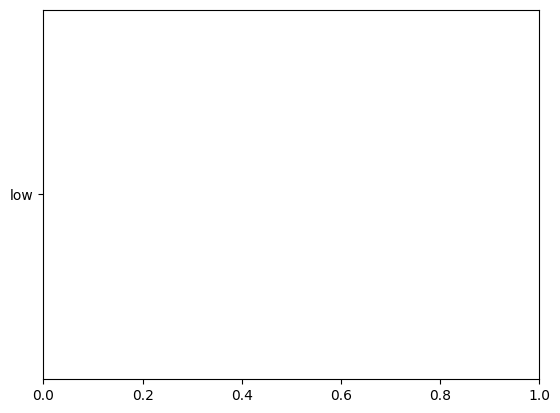

In [53]:
plot_membership_functions()

#### fuzzy rules

In [ ]:
rule1 = ctrl.Rule(price['low'] & mileage['low'] & engine_capacity['medium'] & review['good'], recommendation['recommended'])
rule2 = ctrl.Rule(price['high'] & mileage['high'], recommendation['not_recommended'])
rule3 = ctrl.Rule(review['poor'], recommendation['not_recommended'])
rule4 = ctrl.Rule(price['medium'] & mileage['medium'] & engine_capacity['medium'] & review['average'], recommendation['recommended'])

In [ ]:
# Create and simulate the fuzzy control system
recommendation_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4])
recommendation_sim = ctrl.ControlSystemSimulation(recommendation_ctrl)

In [ ]:
result = fuzzy_df.head(5).apply(lambda r: r['price'], axis=1)
result


1480    120000
1481    120000
837     175000
834     125000
1504    230000
dtype: int64

In [ ]:
def fuzzy_filter(car_details: pd.DataFrame):
    # print(car_details)
    # Fuzzy logic recommendation
    recommendation_sim.input['price'] = car_details['price']
    recommendation_sim.input['mileage'] = car_details['mileage']
    recommendation_sim.input['engine_capacity'] = car_details['engine_capacity']
    recommendation_sim.input['review'] = car_details['review']

    try:
        recommendation_sim.compute()
        print(recommendation_sim.output)
        fuzzy_score = recommendation_sim.output['recommendation']
        print('fuzzy_score = ', fuzzy_score)
        if fuzzy_score > 50:
            fuzzy_recommendation = "Recommended"
        else:
            fuzzy_recommendation = "Not Recommended"
            
        return {
        'id': car_details['id'],
        # 'car_name': car_details['car_name'],
        'recommendations': fuzzy_recommendation,
        'fuzzy_score': fuzzy_score
        }

    except:
        print("Error in computation. Check if inputs are within valid ranges.")

In [ ]:
# user_preferences =   # [price, mileage, engine_capacity, review]
results = fuzzy_df.head(10).apply(fuzzy_filter, axis=1)
print(results)

{'recommendation': np.float64(16.666666666666664)}
fuzzy_score =  16.666666666666664
{'recommendation': np.float64(16.666666666666664)}
fuzzy_score =  16.666666666666664
{'recommendation': np.float64(16.666666666666664)}
fuzzy_score =  16.666666666666664
{'recommendation': np.float64(16.666666666666664)}
fuzzy_score =  16.666666666666664
{'recommendation': np.float64(16.666666666666664)}
fuzzy_score =  16.666666666666664
{'recommendation': np.float64(16.666666666666664)}
fuzzy_score =  16.666666666666664
{'recommendation': np.float64(16.666666666666664)}
fuzzy_score =  16.666666666666664
{'recommendation': np.float64(16.666666666666664)}
fuzzy_score =  16.666666666666664
{'recommendation': np.float64(16.666666666666664)}
fuzzy_score =  16.666666666666664
{'recommendation': np.float64(16.666666666666664)}
fuzzy_score =  16.666666666666664
1480    {'id': 1480, 'recommendations': 'Not Recommend...
1481    {'id': 1481, 'recommendations': 'Not Recommend...
837     {'id': 837, 'recommendatio

c:\Machine Learning Tutorial\Data Preprocessing\.venv\Lib\site-packages\skfuzzy\control\visualization.py:146: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  self.ax.legend(framealpha=0.5)
c:\Machine Learning Tutorial\Data Preprocessing\.venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


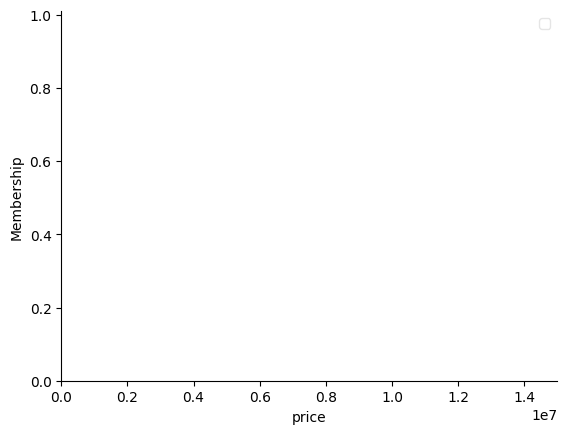

In [ ]:
price.view()

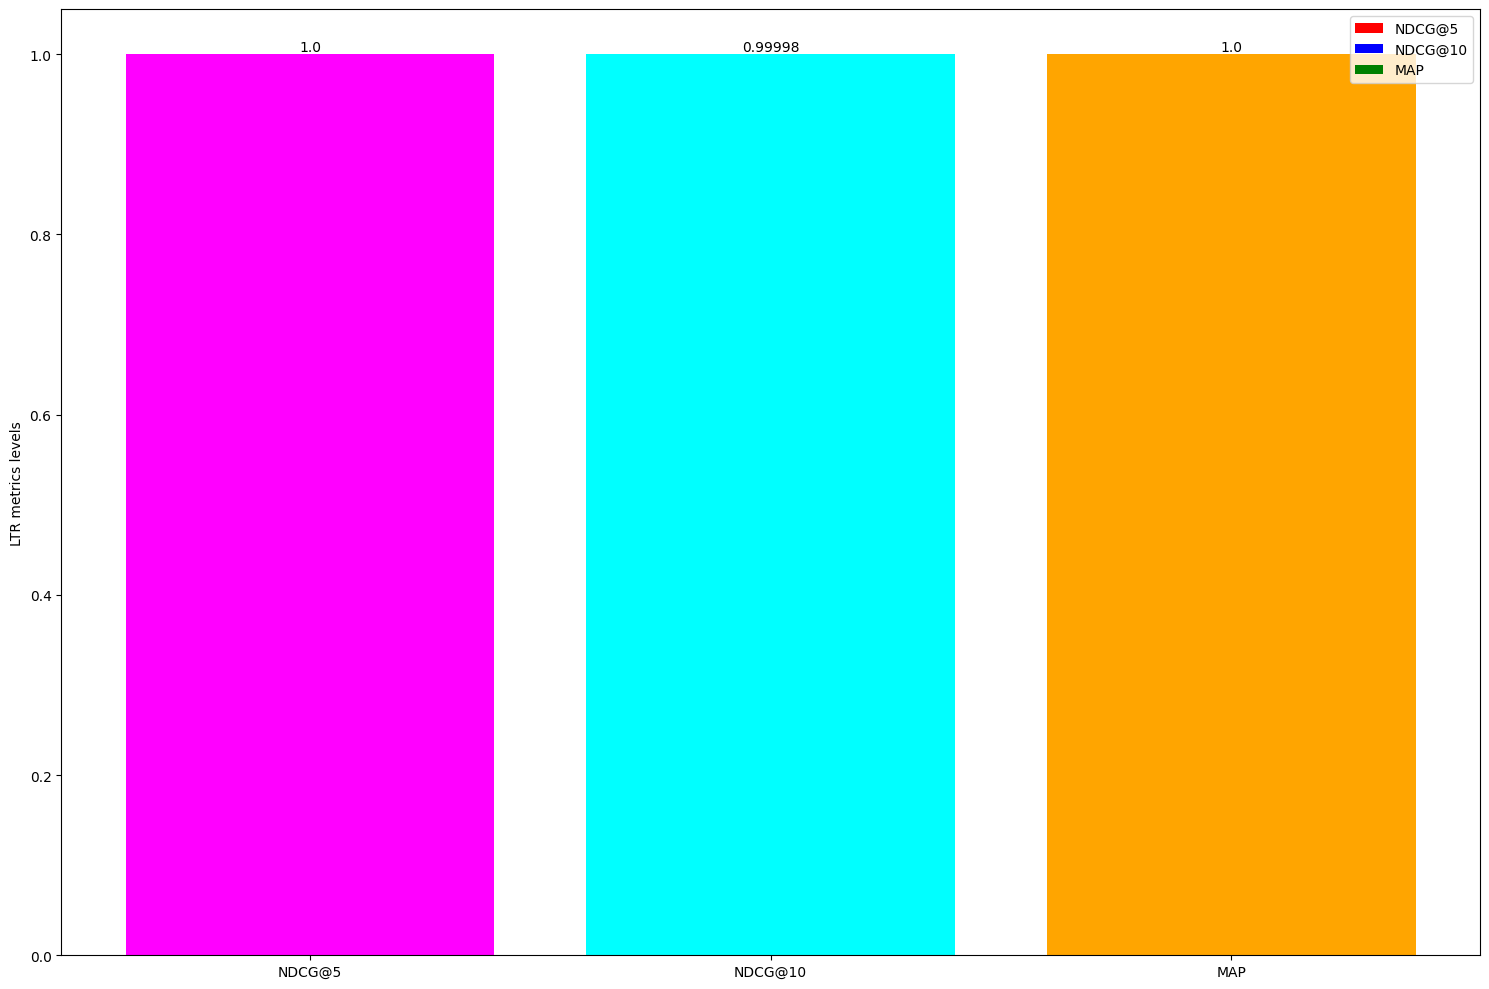

In [ ]:
x_labels = ["NDCG@5", "NDCG@10", "MAP"]
x = np.arange(len(x_labels))
width = 0.2
accuracy = {
    "NDCG@5": 0.988318,
    "NDCG@10": 0.988318,
    "MAP": 1,
}

values1 = [1.0, 0.99998, 1.0]
colors1 = ['red', 'blue', 'green']

values2 = [1.0, 0.99998, 1.0]
colors2 = ['magenta', 'cyan', 'orange']
# Create the bar plot
plt.figure(figsize=(15, 10))
bars1 = plt.bar(x_labels, values1, color=colors1)

bars2 = plt.bar(x_labels, values2, color=colors2)

# Add annotations on top of each bar
for bar in bars1:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height}', ha='center', va='bottom')

# Add labels and title
# plt.xlabel("Items")
plt.ylabel("LTR metrics levels")
plt.title("")
for bar, item in zip(bars1, x_labels):
    bar.set_label(item)
plt.legend(x_labels)

# Show the plot
plt.tight_layout()
plt.show()